# Home Credit Default Risk: improved pipeline
**Goal:** maximise ROC-AUC on the test set, using only `input/train.csv` and `input/test.csv` (no external data, no hand-labelling).

**Result summary (5-fold stratified CV, identical folds):**

| Step | CV AUC |
|---|---|
| Original tutorial (RF, 5 features) | 0.670 |
| LightGBM, all 32 raw features | 0.7505 |
| + engineered features | 0.7591 |
| + Optuna-tuned parameters, fixed rounds (**final**) | **0.7615** |

Contents: 1 Setup, 2 Data checks, 3 Feature engineering, 4 Baseline reproduction, 5 Final model with CV, 6 Feature importance, 7 Submission, 8 Optional tuning, 9 Report.

## 1. Setup

In [1]:
import os, sys, time, json, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
try:
    import lightgbm as lgb
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'])
    import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

SEED = 42
np.random.seed(SEED)

# Google Colab: uncomment and set the folder that contains input/
# from google.colab import drive; drive.mount('/content/drive')
# %cd "/content/drive/MyDrive/WhereThisNotebookIsLocated"

current_dir = Path(os.getcwd())
train_file, test_file = current_dir/'input'/'train.csv', current_dir/'input'/'test.csv'
sample_sub_file = current_dir/'input'/'sample_submission.csv'
assert train_file.exists() and test_file.exists() and sample_sub_file.exists(), 'check the path'
print('lightgbm', lgb.__version__)

lightgbm 4.7.0


## 2. Data checks

In [2]:
train = pd.read_csv(train_file); test = pd.read_csv(test_file); sample_sub = pd.read_csv(sample_sub_file)
y = train['TARGET'].values
print('train', train.shape, '| test', test.shape, '| default rate %.4f' % y.mean())
print('train/test ID overlap:', len(set(train.SK_ID_CURR) & set(test.SK_ID_CURR)))
print('duplicate rows in train:', train.drop(columns='SK_ID_CURR').duplicated().sum())
print('AUC of SK_ID_CURR alone (leakage check, ~0.5 = none): %.4f' % roc_auc_score(y, train.SK_ID_CURR))
miss = pd.DataFrame({'train': train.isnull().mean(), 'test': test.isnull().mean()})
print(miss[(miss > 0).any(axis=1)].round(3))
print('\nDAYS_EMPLOYED == 365243 placeholder: %.1f%% of rows, default rate %.3f vs %.3f for the rest' %
      (100*(train.DAYS_EMPLOYED == 365243).mean(), y[train.DAYS_EMPLOYED == 365243].mean(), y[train.DAYS_EMPLOYED != 365243].mean()))
print('OWN_CAR_AGE values 64/65 (looks capped):', train.OWN_CAR_AGE.isin([64, 65]).sum(), 'rows')

train (171202, 34) | test (61500, 33) | default rate 0.0807
train/test ID overlap: 0


duplicate rows in train: 0
AUC of SK_ID_CURR alone (leakage check, ~0.5 = none): 0.5029
                            train   test
AMT_REQ_CREDIT_BUREAU_HOUR  0.135  0.138
AMT_REQ_CREDIT_BUREAU_MON   0.135  0.138
AMT_REQ_CREDIT_BUREAU_QRT   0.135  0.138
AMT_REQ_CREDIT_BUREAU_YEAR  0.135  0.138
CNT_FAM_MEMBERS             0.000  0.000
EXT_SOURCE_1                0.695  0.698
EXT_SOURCE_2                0.002  0.002
EXT_SOURCE_3                0.319  0.320
OWN_CAR_AGE                 0.660  0.665

DAYS_EMPLOYED == 365243 placeholder: 18.0% of rows, default rate 0.054 vs 0.087 for the rest
OWN_CAR_AGE values 64/65 (looks capped): 1825 rows


**Findings that drive the preprocessing**
- `DAYS_EMPLOYED = 365243` is a placeholder (about 18% of rows, same rows as `ORGANIZATION_TYPE == 'XNA'`). It is converted to missing and flagged. These applicants default *less* often.
- `EXT_SOURCE_1` (~70% missing), `OWN_CAR_AGE` (~66%) and `EXT_SOURCE_3` (~32%) have heavy missingness. Tree models handle NaN natively, so values are not mean-filled.
- The ID carries no signal and train/test IDs do not overlap.

## 3. Feature engineering
All features are row-wise transformations of the provided columns. They use no target and no test-set statistics, so there is nothing to leak.

In [3]:
import numpy as np, pandas as pd

CATS = ["NAME_CONTRACT_TYPE","CODE_GENDER","NAME_INCOME_TYPE","NAME_EDUCATION_TYPE",
        "NAME_FAMILY_STATUS","NAME_HOUSING_TYPE","OCCUPATION_TYPE","ORGANIZATION_TYPE"]
EXT = ["EXT_SOURCE_1","EXT_SOURCE_2","EXT_SOURCE_3"]
GROUPS = ["ORGANIZATION_TYPE","OCCUPATION_TYPE","NAME_INCOME_TYPE","NAME_EDUCATION_TYPE"]

def _safe_div(a, b):
    return (a / b.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)

def basic_clean(d):
    d = d.copy()
    d["DAYS_EMPLOYED_ANOM"] = (d.DAYS_EMPLOYED == 365243).astype(int)
    d.loc[d.DAYS_EMPLOYED == 365243, "DAYS_EMPLOYED"] = np.nan
    d.loc[d.ORGANIZATION_TYPE == "XNA", "ORGANIZATION_TYPE"] = np.nan
    d.loc[d.CODE_GENDER == "XNA", "CODE_GENDER"] = np.nan
    return d

def add_features(d):
    d = basic_clean(d)
    f = pd.DataFrame(index=d.index)
    f["AGE_YEARS"] = -d.DAYS_BIRTH / 365.25
    f["EMPLOYED_YEARS"] = -d.DAYS_EMPLOYED / 365.25
    f["EMPLOYED_RATIO"] = _safe_div(d.DAYS_EMPLOYED, d.DAYS_BIRTH)
    f["REG_RATIO"] = _safe_div(d.DAYS_REGISTRATION, d.DAYS_BIRTH)
    f["IDPUB_RATIO"] = _safe_div(d.DAYS_ID_PUBLISH, d.DAYS_BIRTH)
    f["PHONE_RATIO"] = _safe_div(d.DAYS_LAST_PHONE_CHANGE, d.DAYS_BIRTH)
    f["CAR_AGE_RATIO"] = _safe_div(d.OWN_CAR_AGE, -d.DAYS_BIRTH / 365.25)
    f["CAR_AGE_VS_EMPLOYED"] = d.OWN_CAR_AGE - f.EMPLOYED_YEARS
    f["CAR_AGE_CAPPED"] = d.OWN_CAR_AGE.isin([64, 65]).astype(int)
    f["CREDIT_INCOME"] = _safe_div(d.AMT_CREDIT, d.AMT_INCOME_TOTAL)
    f["ANNUITY_INCOME"] = _safe_div(d.AMT_ANNUITY, d.AMT_INCOME_TOTAL)
    f["CREDIT_TERM"] = _safe_div(d.AMT_CREDIT, d.AMT_ANNUITY)
    f["CREDIT_GOODS"] = _safe_div(d.AMT_CREDIT, d.AMT_GOODS_PRICE)
    f["GOODS_INCOME"] = _safe_div(d.AMT_GOODS_PRICE, d.AMT_INCOME_TOTAL)
    f["DOWN_PAYMENT"] = d.AMT_GOODS_PRICE - d.AMT_CREDIT
    f["INCOME_PER_PERSON"] = _safe_div(d.AMT_INCOME_TOTAL, d.CNT_FAM_MEMBERS)
    f["CREDIT_PER_PERSON"] = _safe_div(d.AMT_CREDIT, d.CNT_FAM_MEMBERS)
    f["ANNUITY_PER_PERSON"] = _safe_div(d.AMT_ANNUITY, d.CNT_FAM_MEMBERS)
    f["CHILD_RATIO"] = _safe_div(d.CNT_CHILDREN, d.CNT_FAM_MEMBERS)
    f["INCOME_PER_YEAR_EMPLOYED"] = _safe_div(d.AMT_INCOME_TOTAL, f.EMPLOYED_YEARS + 1)
    e = d[EXT]
    f["EXT_MEAN"] = e.mean(axis=1); f["EXT_STD"] = e.std(axis=1)
    f["EXT_MIN"] = e.min(axis=1);   f["EXT_MAX"] = e.max(axis=1)
    f["EXT_PROD"] = e.prod(axis=1, skipna=False)
    f["EXT_WEIGHTED"] = (d.EXT_SOURCE_1*2 + d.EXT_SOURCE_2*3 + d.EXT_SOURCE_3*4) / 9
    f["EXT_NA_COUNT"] = e.isnull().sum(axis=1)
    f["EXT_MEAN_X_TERM"] = f.EXT_MEAN * f.CREDIT_TERM
    f["EXT_MEAN_X_AGE"] = f.EXT_MEAN * f.AGE_YEARS
    f["EXT2_X_CREDIT_INCOME"] = d.EXT_SOURCE_2 * f.CREDIT_INCOME
    f["EXT3_X_EMPLOYED"] = d.EXT_SOURCE_3 * f.EMPLOYED_YEARS
    f["EXT_MEAN_X_ANNUITY_INC"] = f.EXT_MEAN * f.ANNUITY_INCOME
    req = [c for c in d.columns if c.startswith("AMT_REQ_CREDIT_BUREAU")]
    f["REQ_TOTAL"] = d[req].sum(axis=1, min_count=1)
    f["REQ_RECENT"] = d[["AMT_REQ_CREDIT_BUREAU_HOUR","AMT_REQ_CREDIT_BUREAU_MON","AMT_REQ_CREDIT_BUREAU_QRT"]].sum(axis=1, min_count=1)
    f["REQ_MISSING"] = d["AMT_REQ_CREDIT_BUREAU_YEAR"].isnull().astype(int)
    f["FLAG_CONTACT_SUM"] = d.FLAG_EMP_PHONE + d.FLAG_WORK_PHONE + d.FLAG_MOBIL
    return pd.concat([d, f], axis=1)


def build(train, test):
    """Returns (Xtr, Xte, cat_cols). Nothing here uses the target."""
    tr, te = add_features(train.drop(columns=["TARGET"], errors="ignore")), add_features(test)
    tr, te = tr.drop(columns=["SK_ID_CURR"]), te.drop(columns=["SK_ID_CURR"])
    for c in CATS:
        cats = sorted(tr[c].dropna().unique())
        tr[c] = pd.Categorical(tr[c], categories=cats); te[c] = pd.Categorical(te[c], categories=cats)
    return tr, te, CATS

In [4]:
X, XT, CAT = build(train, test)
print(X.shape, XT.shape, 'columns identical:', list(X.columns) == list(XT.columns))
num = X.drop(columns=CAT).astype(float)
print('infinite values:', int(np.isinf(num.values).sum()))

(171202, 69) (61500, 69) columns identical: True
infinite values: 0


Group-level statistics (e.g. income relative to the organisation average) and frequency encodings were also tested: CV 0.7582 vs 0.7591 without them, so they were **dropped**.

## 4. Baseline reproduction (original tutorial, 5 features)
Same model as the tutorial (RandomForest, `max_depth=10`) evaluated with the same 5-fold split used for every model below, with preprocessing fitted inside each fold.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(train, y))

def prep_baseline(a_, b_):
    f = ['NAME_CONTRACT_TYPE', 'AMT_INCOME_TOTAL', 'EXT_SOURCE_2', 'OWN_CAR_AGE', 'ORGANIZATION_TYPE']
    a, b = a_[f].copy(), b_[f].copy()
    for d in (a, b): d['NAME_CONTRACT_TYPE'] = d['NAME_CONTRACT_TYPE'].replace({'Cash loans': 0, 'Revolving loans': 1})
    ce = a.ORGANIZATION_TYPE.value_counts(); a['ORGANIZATION_TYPE'] = a.ORGANIZATION_TYPE.map(ce); b['ORGANIZATION_TYPE'] = b.ORGANIZATION_TYPE.map(ce)
    m = a.EXT_SOURCE_2.mean(); a['EXT_SOURCE_2'] = a.EXT_SOURCE_2.fillna(m); b['EXT_SOURCE_2'] = b.EXT_SOURCE_2.fillna(m)
    for d in (a, b):
        d.loc[d.OWN_CAR_AGE >= 60, 'OWN_CAR_AGE'] = np.nan; d['OWN_CAR_AGE'] = d.OWN_CAR_AGE // 10
    oa = pd.get_dummies(a.OWN_CAR_AGE).add_prefix('CAR_'); ob = pd.get_dummies(b.OWN_CAR_AGE).add_prefix('CAR_')
    a = pd.concat([a.drop(columns='OWN_CAR_AGE'), oa], axis=1); b = pd.concat([b.drop(columns='OWN_CAR_AGE'), ob], axis=1)
    return a.values.astype(float), b.reindex(columns=a.columns, fill_value=0).values.astype(float)

base = []
for i, j in folds:
    A, B = prep_baseline(train.iloc[i], train.iloc[j]); s = StandardScaler().fit(A)
    m = RandomForestClassifier(random_state=0, max_depth=10, n_jobs=-1).fit(s.transform(A), y[i])
    base.append(roc_auc_score(y[j], m.predict_proba(s.transform(B))[:, 1]))
print('Baseline RF 5-fold CV AUC: %.4f +/- %.4f' % (np.mean(base), np.std(base)))

Baseline RF 5-fold CV AUC: 0.6698 +/- 0.0019


## 5. Model comparison and final model
All models below used the same 5 folds on the engineered features. These rows are **recorded results from the experiment runs** (the code for them is not repeated here to keep the notebook fast); the final model is re-run live in the next cell.

| Model | CV AUC (mean ± std) | Train AUC |
|---|---|---|
| Tutorial baseline (RF, 5 features) | 0.6698 ± 0.0019 | 0.731 |
| LightGBM, raw 32 features | 0.7505 ± 0.0040 | 0.821 |
| Logistic Regression | 0.7400 ± 0.0041 | 0.743 |
| Extra Trees | 0.7438 ± 0.0033 | 0.872 (overfits) |
| XGBoost | 0.7581 ± 0.0037 | 0.827 |
| LightGBM (default-ish params, early stopping) | 0.7591 ± 0.0035 | 0.836 |
| **LightGBM, Optuna-tuned, fixed rounds** | **0.7615 ± 0.0031** | 0.817 |

Random Forest and CatBoost were started but did not finish in the available compute, so they are **not** in this comparison.

Blending LightGBM/XGBoost/LR/ET with out-of-fold weights gave 0.7616 OOF, but on a split-half stability check it was *below* the best single model (0.7602 vs 0.7607), so **no ensemble is used**.

**Why LightGBM:** best validation AUC, a smaller train/validation gap than the untuned boosted models, native handling of missing values and categoricals, and fast training.

Early stopping on the validation fold makes CV slightly optimistic, so the final model uses a *fixed* number of boosting rounds (chosen from the tuning run), and the validation fold is never used for stopping.

In [6]:
BEST_PARAMS = {
    "num_leaves": 17,
    "min_child_samples": 480,
    "subsample": 0.9977156222028715,
    "colsample_bytree": 0.30564424161592635,
    "reg_lambda": 30.022294228257973,
    "reg_alpha": 4.136104732792231,
    "min_split_gain": 0.49310512704250176,
    "max_bin": 255,
    "cat_smooth": 23.26486564717449
}
N_ROUNDS = 932      # tuning used lr=0.1 (~280 rounds); same budget at lr=0.03
PARAMS = dict(objective='binary', learning_rate=0.03, n_estimators=N_ROUNDS, subsample_freq=1,
              random_state=SEED, n_jobs=-1, verbose=-1, **BEST_PARAMS)

oof = np.zeros(len(X)); test_pred = np.zeros(len(XT)); val_auc, train_auc, gains = [], [], []
t0 = time.time()
for k, (i, j) in enumerate(folds):
    m = lgb.LGBMClassifier(**PARAMS).fit(X.iloc[i], y[i])          # no early stopping on the validation fold
    oof[j] = m.predict_proba(X.iloc[j])[:, 1]
    test_pred += m.predict_proba(XT)[:, 1] / len(folds)
    val_auc.append(roc_auc_score(y[j], oof[j])); train_auc.append(roc_auc_score(y[i], m.predict_proba(X.iloc[i])[:, 1]))
    gains.append(m.booster_.feature_importance('gain'))
    print(f'fold {k}: train {train_auc[-1]:.4f}  valid {val_auc[-1]:.4f}')
print('\nValidation AUC: %.4f +/- %.4f | Train AUC: %.4f | pooled OOF AUC: %.4f | %.0fs' %
      (np.mean(val_auc), np.std(val_auc), np.mean(train_auc), roc_auc_score(y, oof), time.time() - t0))
print('Improvement over baseline: %+.4f AUC' % (np.mean(val_auc) - np.mean(base)))

fold 0: train 0.8174  valid 0.7589


fold 1: train 0.8168  valid 0.7623


fold 2: train 0.8160  valid 0.7666


fold 3: train 0.8177  valid 0.7577


fold 4: train 0.8157  valid 0.7621

Validation AUC: 0.7615 +/- 0.0031 | Train AUC: 0.8167 | pooled OOF AUC: 0.7615 | 188s
Improvement over baseline: +0.0918 AUC


## 6. Feature importance (mean gain across folds)

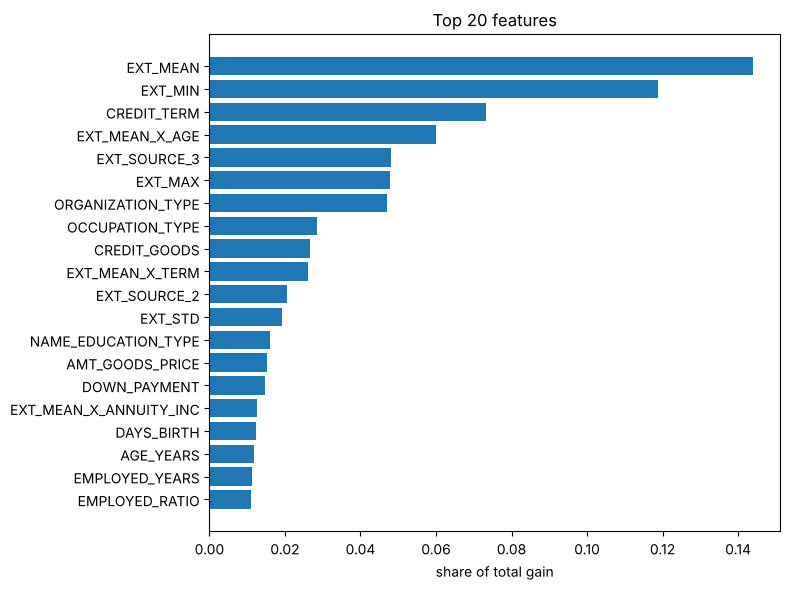

Share of total gain from engineered features: 69.3%
Features with ~zero gain: ['AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'REQ_MISSING', 'DAYS_EMPLOYED_ANOM', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'CAR_AGE_CAPPED']


In [7]:
imp = pd.Series(np.mean(gains, axis=0), index=X.columns).sort_values(ascending=False)
imp.to_csv('feature_importance_gain.csv')
top = imp.head(20)[::-1]
plt.figure(figsize=(8, 6)); plt.barh(top.index, top.values / imp.sum()); plt.xlabel('share of total gain'); plt.title('Top 20 features'); plt.tight_layout(); plt.show()
eng = [c for c in X.columns if c not in train.columns]
print('Share of total gain from engineered features: %.1f%%' % (100 * imp[eng].sum() / imp.sum()))
print('Features with ~zero gain:', list(imp[imp / imp.sum() < 0.0005].index))

## 7. Submission
Average of the 5 fold models' predicted probabilities. Format follows `sample_submission.csv`.

In [8]:
assert (test.SK_ID_CURR.values == sample_sub.SK_ID_CURR.values).all()
sample_sub['TARGET'] = test_pred
output_dir = current_dir / 'output'; os.makedirs(output_dir, exist_ok=True)
output_file = output_dir / 'Submission.csv'
sample_sub.to_csv(output_file, index=False)

# validation of the written file
s, ref = pd.read_csv(output_file), pd.read_csv(sample_sub_file)
assert s.shape == ref.shape and list(s.columns) == list(ref.columns) and (s.SK_ID_CURR.values == ref.SK_ID_CURR.values).all()
assert s.TARGET.notna().all() and np.isfinite(s.TARGET).all() and s.TARGET.between(0, 1).all()
print('submission OK', s.shape, '| TARGET min %.4f mean %.4f max %.4f' % (s.TARGET.min(), s.TARGET.mean(), s.TARGET.max()))

submission OK (61500, 2) | TARGET min 0.0032 mean 0.0889 max 0.7448


## 8. Optional: re-run hyperparameter search (Optuna)
Disabled by default (about 25 minutes on one CPU). The parameters above came from 40 trials at `learning_rate=0.1` with 5-fold CV and early stopping.

In [9]:
RUN_TUNING = False
if RUN_TUNING:
    import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective(t):
        P = dict(objective='binary', learning_rate=0.1, n_estimators=2000, subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1,
                 num_leaves=t.suggest_int('num_leaves', 6, 48), min_child_samples=t.suggest_int('min_child_samples', 40, 500),
                 subsample=t.suggest_float('subsample', 0.6, 1.0), colsample_bytree=t.suggest_float('colsample_bytree', 0.25, 0.8),
                 reg_lambda=t.suggest_float('reg_lambda', 1, 50, log=True), reg_alpha=t.suggest_float('reg_alpha', 1e-3, 10, log=True),
                 min_split_gain=t.suggest_float('min_split_gain', 0, 0.5), max_bin=t.suggest_categorical('max_bin', [127, 255]),
                 cat_smooth=t.suggest_float('cat_smooth', 5, 50))
        a = []
        for i, j in folds:
            m = lgb.LGBMClassifier(**P).fit(X.iloc[i], y[i], eval_set=[(X.iloc[j], y[j])], eval_metric='auc',
                                            callbacks=[lgb.early_stopping(50, verbose=False)])
            a.append(roc_auc_score(y[j], m.predict_proba(X.iloc[j])[:, 1]))
        return np.mean(a)
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0)); study.optimize(objective, n_trials=40)
    print(study.best_value, study.best_params)

## 9. Report: what changed versus the original notebook

| Area | Original | Now |
|---|---|---|
| Features | 5 | 32 raw + engineered ratios, ages, `EXT_SOURCE` statistics/interactions and missingness flags (69 columns) |
| Missing values | `EXT_SOURCE_2` mean-filled, car age bucketed | left as NaN for the trees, with explicit flags where missingness is informative |
| Placeholders | not handled | `DAYS_EMPLOYED = 365243` and `XNA` converted to missing |
| Categoricals | label / count encoding for 2 columns | all 8 handled natively by LightGBM |
| Validation | one 70/30 split | 5-fold stratified CV, identical folds for every model, per-fold AUC, mean ± std, train vs validation |
| Model | RF depth 10 | Optuna-tuned LightGBM with fixed rounds |
| **CV AUC** | **0.670** | **0.7615** |

**Leakage checks:** the ID has no signal (AUC 0.50), train and test IDs do not overlap, no duplicate rows, no feature uses the target, preprocessing uses no test statistics.

**Limits and caveats**
- Hyperparameters were tuned on the same folds that report the final score, so a small optimism of a few thousandths is likely. The public leaderboard is the independent check, but do not tune to it.
- On this single table, about 0.76 to 0.77 looks like a realistic ceiling. A score near 1.0 would indicate leakage or label misuse, not a better model.
- The mean predicted default rate on test (about 8.9%) is slightly higher than the train rate (8.0%). This doesn't affect AUC but may point to a mild train/test shift.

**Reproducibility:** fixed seeds (`SEED = 42`), identical folds, pinned parameters. Results can differ slightly across library versions or CPU counts.